In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import gensim.downloader as api
from gensim.models import Word2Vec
from gensim.models import KeyedVectors
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.manifold import TSNE

In [45]:
pretrained_model: KeyedVectors = api.load("word2vec-google-news-300")
my_model:Word2Vec = KeyedVectors.load("word2vec_sg.model")

In [46]:
words_groups = {
    "animals": ["cat", "dog", "lion", "tiger", "wolf"],
    "professions": ["teacher", "doctor", "driver", "lawyer", "nurse"],
    "cities": ["london", "rome", "egypt", "babylon"],
    "verbs": ["eat", "walk", "drive", "fly", "swim"],
    "adjectives": ["big", "small", "fast", "slow", "happy"]
}

words = sum(words_groups.values(), [])

In [47]:
def get_vectors(model, words):
    vectors = []
    valid_words = []
    
    for w in words:
        if w in model.key_to_index:
            vectors.append(model[w])
            valid_words.append(w)
        else:
            print(f"Word not found: {w}")
    
    return np.array(vectors), valid_words

vec_pre, words_pre = get_vectors(pretrained_model, words)
vec_my, words_my = get_vectors(my_model.wv, words)

In [55]:
sim_pre = cosine_similarity(vec_pre)
sim_my = cosine_similarity(vec_my)

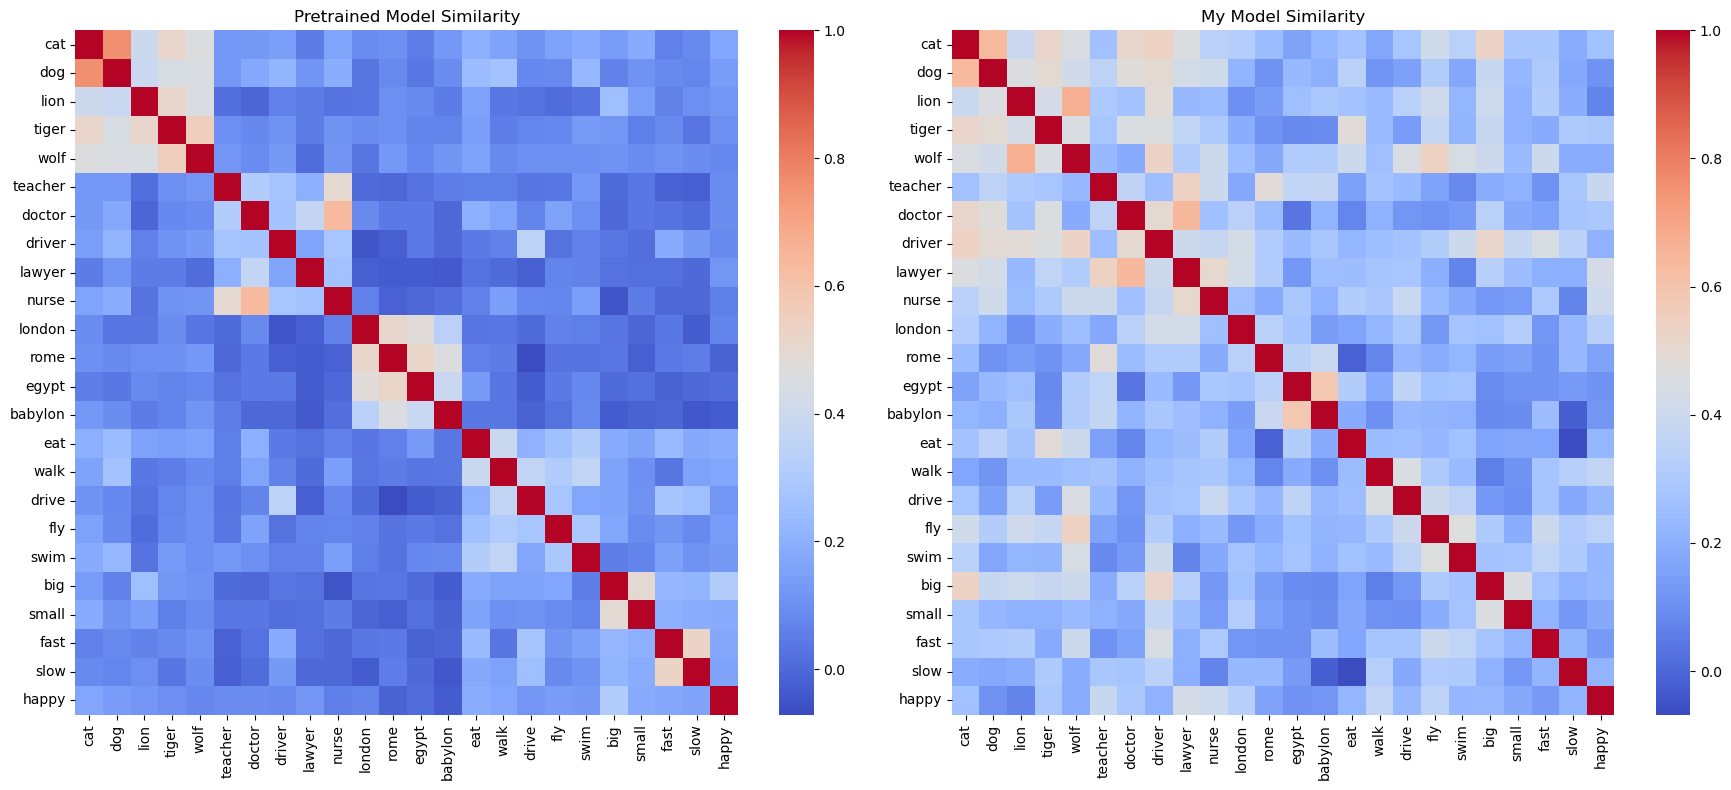

In [64]:
plt.figure(figsize=(18,8))

plt.subplot(1, 2, 1)
sns.heatmap(sim_pre, xticklabels=words_pre, yticklabels=words_pre, cmap="coolwarm")
plt.title("Pretrained Model Similarity")

plt.subplot(1, 2, 2)
sns.heatmap(sim_my, xticklabels=words_my, yticklabels=words_my, cmap="coolwarm")
plt.title("My Model Similarity")

plt.tight_layout()
plt.show()

## 1. Comparison of Distances (Heatmap Analysis)
The pretrained model shows a clear block structure with high within-group similarity and low across-group similarity, indicating effective semantic organization. In contrast, my model displays a less structured pattern with more uniform similarity values and high cross-group similarity, reflecting weak semantic boundaries. This is likely due to training on the Gutenberg literary corpus, which captures contextual co-occurrence rather than strict semantic categories, further limited by the corpus's size and diversity. Overall, the pretrained model has stronger semantic structure, while my model shows weaker discrimination between word meanings.

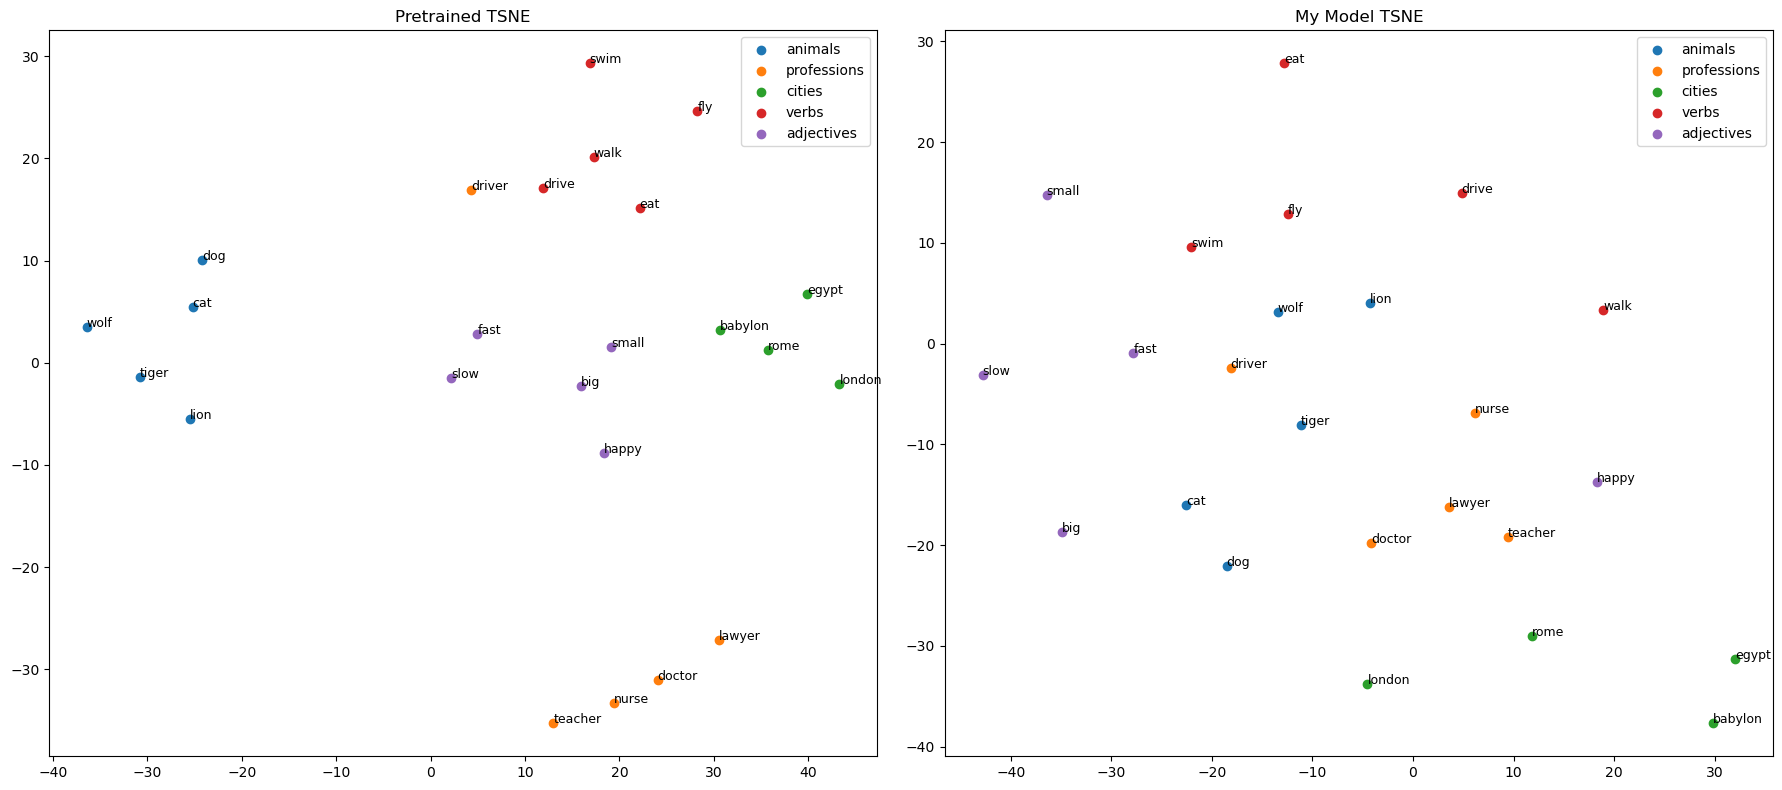

In [65]:
def plot_tsne(vectors, words, groups: dict[str, list[str]], title, ax):
    tsne = TSNE(n_components=2, random_state=42, perplexity=5)
    reduced = tsne.fit_transform(vectors)
    
    for group, group_words in groups.items():
        xs, ys = [], []
        
        for i, w in enumerate(words):
            if w in group_words:
                xs.append(reduced[i, 0])
                ys.append(reduced[i, 1])
        
        ax.scatter(xs, ys, label=group)
        
        for i, w in enumerate(words):
            if w in group_words:
                ax.text(reduced[i, 0], reduced[i, 1], w, fontsize=9)
    
    ax.set_title(title)
    ax.legend()

fig, axes = plt.subplots(1, 2, figsize=(18,8))

plot_tsne(vec_pre, words_pre, words_groups, "Pretrained TSNE", axes[0])
plot_tsne(vec_my, words_my, words_groups, "My Model TSNE", axes[1])

plt.tight_layout()
plt.show()

## 2. Visualization in 2D (TSNE Analysis)
The pretrained model produces clear, well-separated semantic clusters (e.g., animals, professions), demonstrating strong semantic organization. In contrast, my model shows scattered, overlapping distributions with words from the same group often far apart, indicating poor clustering. The main reason is that mymodel was trained on the Gutenberg literary corpus, which captures narrative and stylistic co-occurrences rather than general semantic categories, leading to context-driven rather than semantically-similar embeddings.

In [66]:
def find_neighbors(model:Word2Vec, word, topn=5):
    return model.wv.most_similar(word, topn=topn)

test_words = ["car", "doctor", "paris"]
for w in test_words:
    print(w, find_neighbors(my_model, w))

car [('motor', 0.881096363067627), ('chauffeur', 0.8377938866615295), ('cab', 0.7874107956886292), ('deliberately', 0.7802117466926575), ('ostentatiously', 0.7777390480041504)]
doctor [('hutton', 0.7683725357055664), ('gravely', 0.7466409206390381), ('major', 0.7315542101860046), ('doubtfully', 0.7309384942054749), ('dr', 0.7296350002288818)]
paris [('cannibals', 0.7660133242607117), ('malvoli', 0.7634796500205994), ('british', 0.7568022012710571), ('dubosc', 0.7513900995254517), ('brace', 0.7477278113365173)]


## 3. Anomaly Search
My model frequently produces semantically irrelevant nearest neighbors (e.g., "car" with adverbs like "deliberately"; "doctor" with "gravely"; "paris" with unrelated terms). This happens because the model captures contextual co-occurrence from literary texts rather than true meaning—words often appear together in descriptive sentences. Additionally, limited corpus size and domain lead to unstable representations for rare words like "paris". In contrast, the pretrained model (trained on large, diverse data) yields semantically meaningful neighbors, highlighting the importance of data scale and diversity.